In [ ]:
%pip -q install gymnasium

In [ ]:
import random
from collections import deque

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import trange




class FinalKitchenEnv(gym.Env):
    """
    최종 MDP 규칙을 완벽히 반영한 피자 가게 주방 시뮬레이션 환경 (Gymnasium 기반)
    """
    metadata = {"render_modes": ["human"]}

    def __init__(self):
        super(FinalKitchenEnv, self).__init__()

        # 액션 공간: 5가지 (0: 대기, 1: 도우, 2: 치즈, 3: 페퍼로니, 4: 서빙)
        self.action_space = spaces.Discrete(5)

        # 상태 공간 크기 계산:
        # p(2) * c(2) * r(2) * m1(3) * t1(9) * m2(3) * t2(9) = 5,832 상태
        self.observation_space = spaces.Discrete(2 * 2 * 2 * 3 * 9 * 3 * 9)

        self.reset()

    def _get_obs_to_id(self):
        """
        7개의 상태 변수를 하나의 고유한 정수 ID(0 ~ 5831)로 매핑
        State: [p, c, r, m1, t1, m2, t2]
        """
        # 각 변수의 범위 검증 및 인코딩
        p_val = self.plate_p
        c_val = self.plate_c
        r_val = self.plate_r
        m1_val = self.order_m1
        t1_val = self.time_t1
        m2_val = self.order_m2
        t2_val = self.time_t2

        # 고유 ID 계산 (가중치 방식)
        state_id = (
            p_val * (2 * 2 * 3 * 9 * 3 * 9) +
            c_val * (2 * 3 * 9 * 3 * 9) +
            r_val * (3 * 9 * 3 * 9) +
            m1_val * (9 * 3 * 9) +
            t1_val * (3 * 9) +
            m2_val * 9 +
            t2_val
        )
        return state_id

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        # 조리대 초기화 (p, c, r) = (0, 0, 0)
        self.plate_p = 0
        self.plate_c = 0
        self.plate_r = 0

        # 초기 주문 2개 생성 (메뉴: 1(치즈피자) 또는 2(페퍼로니피자), 0은 주문없음)
        # 4~8스텝의 제한 시간 부여
        self.order_m1 = random.choice([1, 2])
        self.time_t1 = random.randint(4, 8)

        self.order_m2 = random.choice([1, 2])
        self.time_t2 = random.randint(4, 8)

        return self._get_obs_to_id(), {}

    def step(self, action):
        reward = -0.1  # 모든 행동의 기본 비용
        terminated = False
        truncated = False

        # 1. 서빙 액션(4)인 경우, 서빙 성공 여부를 먼저 확인
        if action == 4:
            # 현재 조리대의 재료 조합 확인
            # 치즈피자: 도우(1)->치즈(1), 페퍼로니피자: 도우(1)->치즈(1)->페퍼로니(1)
            is_cheese_pizza = (self.plate_p == 1 and self.plate_c == 1 and self.plate_r == 0)
            is_pepperoni_pizza = (self.plate_p == 1 and self.plate_c == 1 and self.plate_r == 1)

            served_menu = 0
            if is_cheese_pizza:
                served_menu = 1
            elif is_pepperoni_pizza:
                served_menu = 2

            # 일치하는 주문을 접수 순서대로 검사한다. 같은 메뉴이면 주문 1 우선.
            target_slot = 0
            if served_menu != 0:
                if self.order_m1 == served_menu:
                    target_slot = 1
                elif self.order_m2 == served_menu:
                    target_slot = 2

            if target_slot != 0:
                reward += 20.0  # 정확한 피자 서빙 성공
                # 해당 주문 완료 처리 (0으로 변경)
                if target_slot == 1:
                    self.order_m1 = 0
                    self.time_t1 = 0
                else:
                    self.order_m2 = 0
                    self.time_t2 = 0

                # 서빙 성공 시 조리대 재료 유지 여부 또는 리셋 규칙 확인 (기본적으로 성공 시 조리대 비워짐)
                self.plate_p, self.plate_c, self.plate_r = 0, 0, 0
            else:
                # 잘못된 서빙 (메뉴 불일치 또는 대기 주문이 없는데 서빙한 경우)
                reward -= 15.0
                # 조리대 모든 재료 제거, 대기 주문 유지, 에피소드 즉시 종료 안 함
                self.plate_p, self.plate_c, self.plate_r = 0, 0, 0

        # 2. 재료 추가 및 기타 액션 처리
        elif action == 1:  # 도우 올리기
            if self.plate_p == 0:
                self.plate_p = 1
            else:
                reward -= 2.0  # 동일한 재료 중복 추가 페널티

        elif action == 2:  # 치즈 뿌리기
            if self.plate_p == 1 and self.plate_c == 0:
                self.plate_c = 1
            elif self.plate_p == 0:
                reward -= 2.0  # 잘못된 재료 순서 (도우 없이 치즈)
            else:
                reward -= 2.0  # 중복 추가

        elif action == 3:  # 페퍼로니 올리기
            if self.plate_p == 1 and self.plate_c == 1 and self.plate_r == 0:
                self.plate_r = 1
            elif self.plate_p == 0 or self.plate_c == 0:
                reward -= 2.0  # 잘못된 재료 순서
            else:
                reward -= 2.0  # 중복 추가

        elif action == 0:  # 대기에도 공통 비용만 적용
            pass

        # 3. 모든 행동 공통: 대기 중인 주문의 남은 시간 각각 1씩 감소
        if self.order_m1 != 0:
            self.time_t1 -= 1
            if self.time_t1 <= 0:
                reward -= 10.0  # 시간 초과 페널티
                self.order_m1 = 0
                self.time_t1 = 0
                # 주문이 취소되어도 조리대의 재료는 유지됨

        if self.order_m2 != 0:
            self.time_t2 -= 1
            if self.time_t2 <= 0:
                reward -= 10.0  # 시간 초과 페널티
                self.order_m2 = 0
                self.time_t2 = 0
                # 주문이 취소되어도 조리대의 재료는 유지됨

        # 4. 에피소드 종료 조건 확인: 모든 대기 주문이 완료되거나 취소되어 0개가 된 경우
        if self.order_m1 == 0 and self.order_m2 == 0:
            terminated = True

        state_id = self._get_obs_to_id()
        return state_id, reward, terminated, truncated, {}

In [ ]:
# =========================
# 0. Observation Wrapper
# =========================
class KitchenDQNObservation(gym.ObservationWrapper):
    """FinalKitchenEnv의 정수 상태 ID를 DQN 입력으로 변환한다."""

    def __init__(self, env):
        super().__init__(env)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(7,), dtype=np.float32
        )

    def observation(self, state_id):
        # 원본 _get_obs_to_id()에서 사용한 진법의 역순으로 복원한다.
        state = np.unravel_index(state_id, (2, 2, 2, 3, 9, 3, 9))
        scale = np.array([1, 1, 1, 2, 8, 2, 8], dtype=np.float32)
        return np.asarray(state, dtype=np.float32) / scale


# =========================
# 1. Neural Network (Q-Network)
# =========================
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity=20000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)

# =========================
# 3. DQN Agent
# =========================
class DQNAgent:
    def __init__(self, state_dim, action_dim, lr=1e-3, gamma=0.99, eps_start=1.0, eps_end=0.05, eps_decay=7_500):
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = eps_start
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay = eps_decay
        self.step_count = 0

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.q_net = DQN(state_dim, action_dim).to(self.device)
        self.target_net = DQN(state_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)

    def select_action(self, state):
        self.step_count += 1
        self.epsilon = self.eps_start + min(1.0, (self.step_count - 1) / self.eps_decay) * (self.eps_end - self.eps_start)
        if random.random() < self.epsilon:
            return random.randint(0, self.action_dim - 1)
        else:
            return self.act_greedy(state)

    @torch.no_grad()
    def act_greedy(self, state):
        """Used for evaluation (no exploration)."""
        state = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        q_values = self.q_net(state)
        return torch.argmax(q_values, dim=1).item()

    def update(self, replay_buffer, batch_size):
        if len(replay_buffer) < batch_size:
            return

        states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)
        states, actions, rewards, next_states, dones = (
            torch.as_tensor(states, device=self.device),
            torch.as_tensor(actions, device=self.device),
            torch.as_tensor(rewards, device=self.device),
            torch.as_tensor(next_states, device=self.device),
            torch.as_tensor(dones, device=self.device),
        )

        with torch.no_grad():
            max_next_q = self.target_net(next_states).max(1)[0]
            target_q = rewards + (1 - dones) * self.gamma * max_next_q

        current_q = self.q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(current_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    def update_target_network(self):
        self.target_net.load_state_dict(self.q_net.state_dict())

# =========================
# 4. Evaluation Function
# =========================
def evaluate_agent(agent, env_factory, episodes=100, seed=101):
    """원본 환경에서 같은 초기 주문을 뽑아 탐험 없이 평가한다."""
    training_random_state = random.getstate()
    random.seed(seed)
    env = KitchenDQNObservation(env_factory())
    total_reward = total_orders = served = expired = 0
    try:
        for _ in range(episodes):
            state, _ = env.reset()
            pending = int(np.count_nonzero(state[[3, 5]]))
            total_orders += pending

            while True:
                action = agent.act_greedy(state)
                state, reward, terminated, truncated, _ = env.step(action)
                total_reward += reward
                # 원본 환경에서 양수 보상이 발생하는 행동은 성공한 서빙뿐이다.
                served_now = int(action == 4 and reward > 0)
                remaining = int(np.count_nonzero(state[[3, 5]]))
                served += served_now
                expired += pending - remaining - served_now
                pending = remaining
                if terminated or truncated:
                    break
    finally:
        env.close()
        random.setstate(training_random_state)

    return {
        "평균 에피소드 보상": total_reward / episodes,
        "주문 성공률": served / total_orders,
        "시간 초과율": expired / total_orders,
    }


# =========================
# 5. Training Loop
# =========================
def train_dqn(env_factory, total_steps=15_000, test_interval=3_000, seed=42):
    random.seed(seed)
    torch.manual_seed(seed)
    env = KitchenDQNObservation(env_factory())
    agent = DQNAgent(env.observation_space.shape[0], env.action_space.n,
                     eps_decay=max(1, total_steps // 2))
    replay_buffer = ReplayBuffer(capacity=20_000)
    batch_size = 64
    target_update_freq = 250

    test_steps, test_scores = [], []
    state, _ = env.reset(seed=seed)
    for step in trange(1, total_steps + 1, desc="Training"):
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        replay_buffer.push(state, action, reward, next_state, terminated)
        agent.update(replay_buffer, batch_size)

        if terminated or truncated:
            state, _ = env.reset()
        else:
            state = next_state

        if step % target_update_freq == 0:
            agent.update_target_network()

        if step % test_interval == 0 or step == total_steps:
            metrics = evaluate_agent(agent, env_factory)
            test_steps.append(step)
            test_scores.append(metrics["평균 에피소드 보상"])
            print(f"\n{step:,} steps | 평균 보상 {metrics['평균 에피소드 보상']:.2f} | "
                  f"주문 성공률 {metrics['주문 성공률']:.1%} | "
                  f"시간 초과율 {metrics['시간 초과율']:.1%}")

    env.close()
    return agent, test_steps, test_scores

Training:   0%|          | 0/15000 [00:00<?, ?it/s]


3,000 steps | 평균 보상 -2.59 | 주문 성공률 47.0% | 시간 초과율 53.0%

6,000 steps | 평균 보상 18.15 | 주문 성공률 66.0% | 시간 초과율 34.0%

9,000 steps | 평균 보상 22.03 | 주문 성공률 71.0% | 시간 초과율 29.0%

12,000 steps | 평균 보상 21.54 | 주문 성공률 70.5% | 시간 초과율 29.5%

15,000 steps | 평균 보상 22.90 | 주문 성공률 72.5% | 시간 초과율 27.5%


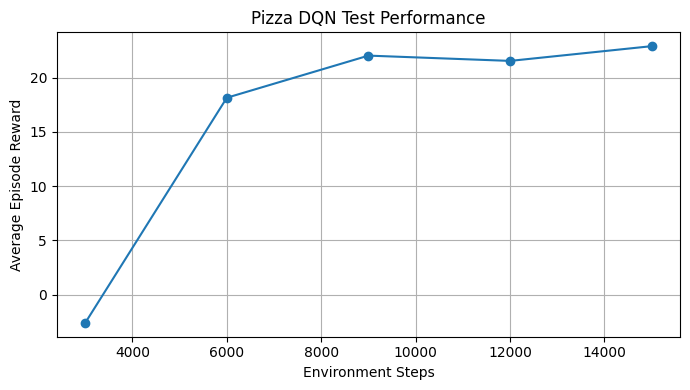

In [ ]:
if __name__ == "__main__":
    torch.set_num_threads(1)
    agent, test_steps, test_scores = train_dqn(FinalKitchenEnv)

    plt.figure(figsize=(7, 4))
    plt.plot(test_steps, test_scores, marker="o")
    plt.title("Pizza DQN Test Performance")
    plt.xlabel("Environment Steps")
    plt.ylabel("Average Episode Reward")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# 학습이 끝난 뒤 실행하여 행동을 확인한다.
def show_dqn_play(agent, episodes=5, seed=101):
    action_names = ["대기", "도우 추가", "치즈 추가", "페퍼로니 추가", "서빙"]
    scale = np.array([1, 1, 1, 2, 8, 2, 8], dtype=np.float32)
    saved_random_state = random.getstate()
    random.seed(seed)
    env = KitchenDQNObservation(FinalKitchenEnv())
    try:
        for episode in range(episodes):
            state, _ = env.reset()
            total_reward = 0.0
            step = 0
            print(f"\n========== 게임 {episode + 1} ==========")
            while True:
                step += 1
                raw = np.rint(state * scale).astype(int)
                p, c, r, m1, t1, m2, t2 = raw
                menu = {(1, 1, 0): 1, (1, 1, 1): 2}.get((p, c, r), 0)
                can_serve = menu != 0 and menu in (m1, m2)
                with torch.no_grad():
                    tensor = torch.as_tensor(
                        state, dtype=torch.float32, device=agent.device
                    ).unsqueeze(0)
                    values = agent.q_net(tensor)[0].cpu().numpy()
                action = int(np.argmax(values))
                print(f"\n[{step}스텝] 상태 [p,c,r,m1,t1,m2,t2] = {raw.tolist()}")
                print("Q값", dict(zip(action_names, np.round(values, 2).tolist())))
                print("선택", action_names[action])
                if can_serve and action != 4:
                    print("★ 서빙 가능하지만 다른 행동 선택")
                next_state, reward, terminated, truncated, _ = env.step(action)
                served = int(action == 4 and can_serve)
                before = int(m1 != 0) + int(m2 != 0)
                after = int(np.count_nonzero(next_state[[3, 5]]))
                expired = before - after - served
                if action == 4:
                    print("서빙 성공" if served else "잘못된 서빙")
                if expired:
                    print(f"시간 초과 {expired}건")
                print(f"이번 보상 {reward:.2f}")
                total_reward += reward
                state = next_state
                if terminated or truncated:
                    print(f"게임 종료 | 총 보상 {total_reward:.2f}")
                    break
    finally:
        env.close()
        random.setstate(saved_random_state)


show_dqn_play(agent)



========== 게임 1 ==========

[1스텝] 상태 [p,c,r,m1,t1,m2,t2] = [0, 0, 0, 1, 8, 1, 8]
Q값 {'대기': 37.06999969482422, '도우 추가': 42.33000183105469, '치즈 추가': 30.149999618530273, '페퍼로니 추가': 35.810001373291016, '서빙': 20.75}
선택 도우 추가
이번 보상 -0.10

[2스텝] 상태 [p,c,r,m1,t1,m2,t2] = [1, 0, 0, 1, 7, 1, 7]
Q값 {'대기': 37.33000183105469, '도우 추가': 30.770000457763672, '치즈 추가': 42.29999923706055, '페퍼로니 추가': 35.79999923706055, '서빙': 11.079999923706055}
선택 치즈 추가
이번 보상 -0.10

[3스텝] 상태 [p,c,r,m1,t1,m2,t2] = [1, 1, 0, 1, 6, 1, 6]
Q값 {'대기': 39.630001068115234, '도우 추가': 32.40999984741211, '치즈 추가': 42.22999954223633, '페퍼로니 추가': 32.81999969482422, '서빙': 42.599998474121094}
선택 서빙
서빙 성공
이번 보상 19.90

[4스텝] 상태 [p,c,r,m1,t1,m2,t2] = [0, 0, 0, 0, 0, 1, 5]
Q값 {'대기': 20.43000030517578, '도우 추가': 19.639999389648438, '치즈 추가': 14.15999984741211, '페퍼로니 추가': 14.760000228881836, '서빙': 8.710000038146973}
선택 대기
이번 보상 -0.10

[5스텝] 상태 [p,c,r,m1,t1,m2,t2] = [0, 0, 0, 0, 0, 1, 4]
Q값 {'대기': 10.670000076293945, '도우 추가': 17.68000030517578, '치즈 